In [57]:
import numpy as np 
import matplotlib.pyplot as plt 
from scipy.interpolate import CubicSpline

In [58]:
datos = np.genfromtxt('datos-01.txt')
x0 = datos[:,0]
y0 = datos[:,1]

N = len(y0)-1
h = x0[1]-x0[0]

M = 4*np.eye(N-2)+np.eye(N-2,k=1)+np.eye(N-2,k=-1)

Y = 3/h**2*(y0[:-3] -2*y0[1:-2] +y0[2:-1])

Bsolve = np.linalg.solve(M,Y)
B = np.zeros(N)
B[1:-1]=Bsolve
print(B)


[ 0.  -3.6  2.4  0. ]


In [59]:
print(y0[:-3], y0[1:-2], y0[2:-1])
print(y0)

[1. 4.] [4. 3.] [3. 4.]
[1. 4. 3. 4. 5.]


In [60]:
print(M)

[[4. 1.]
 [1. 4.]]


In [61]:
a = np.zeros(N)
a[:-1] = (B[1:]-B[:-1])/(3*h)
print(a)

[-1.2  2.  -0.8  0. ]


In [62]:
c = np.zeros(N)
c[:-1] = 1/h*(y0[1:-1]-y0[:-2])-h/3*(B[1:]+2*B[:-1])
print(c)

[ 4.2  0.6 -0.6  0. ]


In [63]:
c[-1] = c[-2]+3*a[-2]*h**2+2*B[-2]*h
print(c)
a[-1] = (h*c[-1]-y0[0]+y0[-1])/2*h**3
print(a)

[ 4.2  0.6 -0.6  1.8]
[-1.2  2.  -0.8  2.9]


In [64]:
B[-1]=-3*h*a[-1] #Aqui puede haber un error ya que no pide guardar el valor de B final sino lo ocupamos para calcular los coeficientes
print(B) 

[ 0.  -3.6  2.4 -8.7]


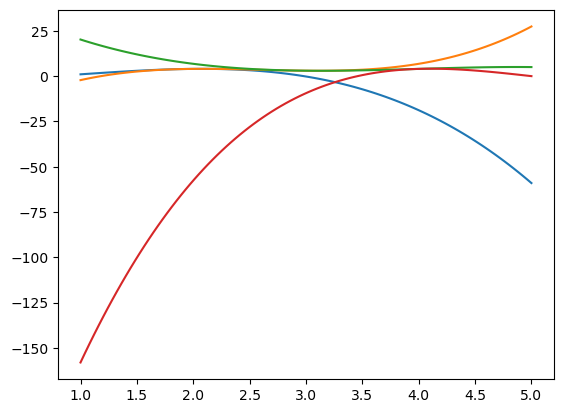

In [65]:
xx = np.linspace(x0[0],x0[-1],100)  
S= np.zeros(N)
for n in range(N):
    xx = np.linspace(x0[0],x0[-1],100)  
    plt.plot(xx,a[n]*(xx-x0[n])**3+B[n]*(xx-x0[n])**2+c[n]*(xx-x0[n])+y0[n]) #Error malo
#print(S)

In [67]:
print(x0,x0[-1])

[1. 2. 3. 4. 5.] 5.0


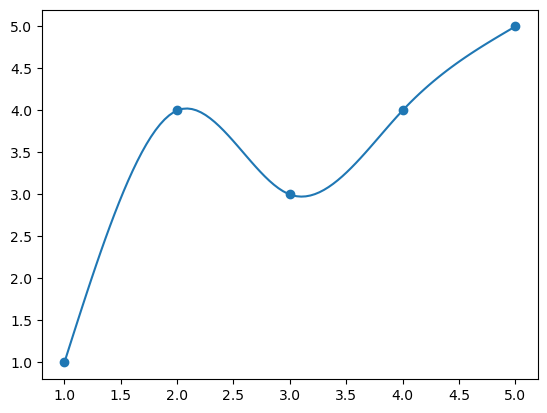

In [66]:
plt.scatter(x0,y0)
x = np.linspace(min(x0),max(x0),100)
cs = CubicSpline(x0,y0,bc_type='natural')
plt.plot(x,cs(x))